# Exercise 1: Deterministic vs. Slippery Ice Physics

In [1]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [ ]:
def one_hot_encode(state: int, num_states: int, dev: torch.device) -> torch.Tensor:
    vec = torch.zeros(num_states, dtype=torch.float32, device=dev)
    vec[state] = 1.0
    return vec

class DQN(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        batch = random.sample(self.buffer, batch_size)
        return zip(*batch)

    def __len__(self) -> int:
        return len(self.buffer)

class FrozenLakeDQNAgent:
    def __init__(self, num_states: int, num_actions: int, dev: torch.device, lr: float = 1e-3):
        self.num_states = num_states
        self.num_actions = num_actions
        self.device = dev
        self.policy_net = DQN(num_states, num_actions, 64).to(dev) # policy network
        self.target_net = DQN(num_states, num_actions, 64).to(dev) # target network is same as above, since it has to be that wayyy.  
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr) # optimizer here, m
        self.loss_fn = nn.MSELoss()
        self.memory = ReplayBuffer(10000) # dequeu wala replay
        self.epsilon = 1.0 # 100% random action

    def select_action(self, state: int, greedy: bool = False) -> int:
        if not greedy and random.random() < self.epsilon:
            return random.randrange(self.num_actions)
        with torch.no_grad():
            s_t = one_hot_encode(state, self.num_states, self.device).unsqueeze(0)
            return int(torch.argmax(self.policy_net(s_t), dim=1).item())

    def get_all_q_values(self) -> np.ndarray:
        with torch.no_grad():
            eye = torch.eye(self.num_states, dtype=torch.float32, device=self.device)
            return self.policy_net(eye).cpu().numpy()

    def update(self) -> float:
        if len(self.memory) < 64:
            return 0.0
        s, a, r, ns, d = self.memory.sample(64)
        s_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in s])
        ns_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in ns])
        a_b = torch.tensor(a, dtype=torch.int64, device=self.device).unsqueeze(1)
        r_b = torch.tensor(r, dtype=torch.float32, device=self.device).unsqueeze(1)
        d_b = torch.tensor(d, dtype=torch.float32, device=self.device).unsqueeze(1)

        cur_q = self.policy_net(s_b).gather(1, a_b)
        with torch.no_grad():
            max_ns_q = self.target_net(ns_b).max(dim=1, keepdim=True)[0]
            tgt_q = r_b + (0.99 * max_ns_q * (1.0 - d_b))

        loss = self.loss_fn(cur_q, tgt_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return float(loss.item())

    def sync_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())


In [ ]:
# Run both Deterministic (IS_SLIPPERY=False) and Slippery (IS_SLIPPERY=True)
def run_training(is_slippery: bool, num_episodes: int, eps_decay: float, seed: int = 42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    # 1 here creating the frozen lake instance
    env = gym.make("FrozenLake-v1", is_slippery=is_slippery)
    agent = FrozenLakeDQNAgent(16, 4, device)
    rewards_history, epsilons_history = [], []

    print(f"Starting Training: is_slippery={is_slippery}, episodes={num_episodes}, decay={eps_decay}")
    for ep in range(1, num_episodes + 1):
        s, _ = env.reset(seed=seed + ep)
        done = False
        ep_r = 0.0
        while not done:
            a = agent.select_action(s)
            ns, r, term, trunc, _ = env.step(a)
            done = term or trunc
            agent.memory.push(s, a, r, ns, done)
            agent.update()
            s = ns
            ep_r += r
        agent.epsilon = max(0.01, agent.epsilon * eps_decay)
        rewards_history.append(ep_r)
        epsilons_history.append(agent.epsilon)
        if ep % 20 == 0:
            agent.sync_target_network()
        if ep % (500 if is_slippery else 100) == 0:
            r50 = np.mean(rewards_history[-50:]) * 100
            print(f"Episode {ep:4d}/{num_episodes} | Success (last 50): {r50:5.1f}% | Epsilon: {agent.epsilon:.3f}")

    q_table = agent.get_all_q_values()
    env.close()
    return rewards_history, epsilons_history, q_table, agent

# 1. Deterministic run
r_det, eps_det, q_det, agent_det = run_training(is_slippery=False, num_episodes=600, eps_decay=0.995)

# 2. Slippery run (Exercise 1 parameters)
r_slip, eps_slip, q_slip, agent_slip = run_training(is_slippery=True, num_episodes=2500, eps_decay=0.998)


Starting Training: is_slippery=False, episodes=600, decay=0.995
Episode  100/600 | Success (last 50):  14.0% | Epsilon: 0.606
Episode  200/600 | Success (last 50):  12.0% | Epsilon: 0.367
Episode  300/600 | Success (last 50):  50.0% | Epsilon: 0.222
Episode  400/600 | Success (last 50):  82.0% | Epsilon: 0.135
Episode  500/600 | Success (last 50):  86.0% | Epsilon: 0.082
Episode  600/600 | Success (last 50):  94.0% | Epsilon: 0.049
Starting Training: is_slippery=True, episodes=2500, decay=0.998
Episode  500/2500 | Success (last 50):   8.0% | Epsilon: 0.368
Episode 1000/2500 | Success (last 50):  20.0% | Epsilon: 0.135
Episode 1500/2500 | Success (last 50):  54.0% | Epsilon: 0.050
Episode 2000/2500 | Success (last 50):  66.0% | Epsilon: 0.018
Episode 2500/2500 | Success (last 50):  54.0% | Epsilon: 0.010


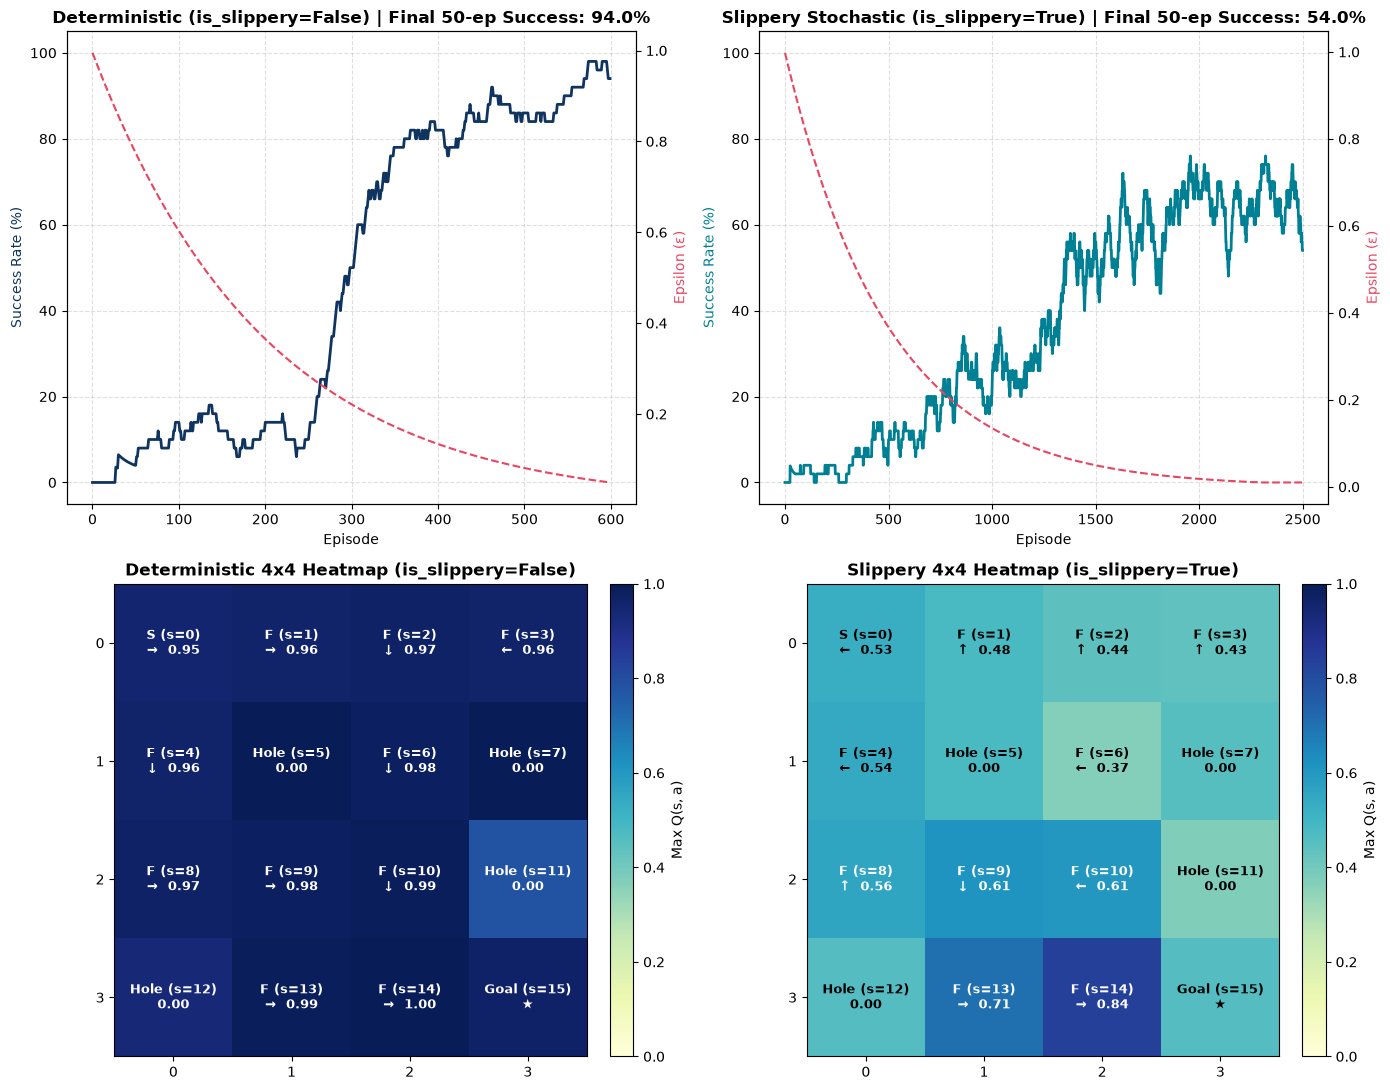

In [4]:
# Visual Comparison Dashboard: Learning Curves & Heatmaps
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Deterministic Success Curve
ax1 = axes[0, 0]
roll_det = [np.mean(r_det[max(0, i-49):i+1]) * 100 for i in range(len(r_det))]
ax1.plot(roll_det, color="#0f3460", linewidth=2, label="Success Rate (50-ep avg)")
ax1.set_xlabel("Episode")
ax1.set_ylabel("Success Rate (%)", color="#0f3460")
ax1.set_ylim(-5, 105)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1_twin = ax1.twinx()
ax1_twin.plot(eps_det, color="#e94560", linestyle="--", linewidth=1.5, label="Epsilon")
ax1_twin.set_ylabel("Epsilon (ε)", color="#e94560")
ax1.set_title(f"Deterministic (is_slippery=False) | Final 50-ep Success: {roll_det[-1]:.1f}%", fontweight="bold")

# Slippery Success Curve
ax2 = axes[0, 1]
roll_slip = [np.mean(r_slip[max(0, i-49):i+1]) * 100 for i in range(len(r_slip))]
ax2.plot(roll_slip, color="#008094", linewidth=2, label="Success Rate (50-ep avg)")
ax2.set_xlabel("Episode")
ax2.set_ylabel("Success Rate (%)", color="#008094")
ax2.set_ylim(-5, 105)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2_twin = ax2.twinx()
ax2_twin.plot(eps_slip, color="#e94560", linestyle="--", linewidth=1.5, label="Epsilon")
ax2_twin.set_ylabel("Epsilon (ε)", color="#e94560")
ax2.set_title(f"Slippery Stochastic (is_slippery=True) | Final 50-ep Success: {roll_slip[-1]:.1f}%", fontweight="bold")

# Heatmap function
grid_labels = [["S", "F", "F", "F"], ["F", "H", "F", "H"], ["F", "F", "F", "H"], ["H", "F", "F", "G"]]
arrow_map = {0: "←", 1: "↓", 2: "→", 3: "↑"}

def draw_heatmap(ax, q_table, title):
    max_q = np.max(q_table, axis=1).reshape(4, 4)
    best_act = np.argmax(q_table, axis=1).reshape(4, 4)
    im = ax.imshow(max_q, cmap="YlGnBu", vmin=0.0, vmax=1.0)
    for r in range(4):
        for c in range(4):
            tile = grid_labels[r][c]
            val = max_q[r, c]
            arrow = arrow_map[best_act[r, c]]
            color = "white" if val > 0.55 else "black"
            s = r * 4 + c
            if tile == "H":
                lbl = f"Hole (s={s})\n0.00"
            elif tile == "G":
                lbl = f"Goal (s=15)\n★"
            else:
                lbl = f"{tile} (s={s})\n{arrow}  {val:.2f}"
            ax.text(c, r, lbl, ha="center", va="center", color=color, fontweight="bold", fontsize=9)
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_title(title, fontweight="bold")
    return im

im1 = draw_heatmap(axes[1, 0], q_det, "Deterministic 4x4 Heatmap (is_slippery=False)")
fig.colorbar(im1, ax=axes[1, 0], fraction=0.046, pad=0.04, label="Max Q(s, a)")

im2 = draw_heatmap(axes[1, 1], q_slip, "Slippery 4x4 Heatmap (is_slippery=True)")
fig.colorbar(im2, ax=axes[1, 1], fraction=0.046, pad=0.04, label="Max Q(s, a)")

plt.tight_layout()
plt.show()


**Inspect tile $s = 6$ (between Holes 5 and 7) and tile $s = 14$ (next to Hole 12 and Goal 15). Why do the learned greedy arrows change direction under `IS_SLIPPERY = True`, and why is $\max_a Q(0, a)$ much lower than $\gamma^5 \approx 0.95$?**

* **Tile $s=6$:** Choosing Down gives a 2/3 chance of slipping sideways into Hole 5 or Hole 7 (immediate death). Aiming Left (or Up) is safer because perpendicular slips land on safe frozen tiles (tiles 2 and 10).
* **Tile $s=14$:** Aiming Right leads straight to the Goal, and perpendicular slips hit safe tile 10 or bounce harmlessly off the bottom wall. Because Hole 12 is directly opposite (Left), there is a 0% chance of slipping backward into it.
* **Why $\max_a Q(0, a) \ll \gamma^5 \approx 0.95$:** In slippery mode, survival is not guaranteed (max success rate is ~75%), and paths take 20–35 steps instead of 5–6. Heavy discount factor decay ($\gamma^{30} \approx 0.74$) combined with the lower success rate drops $Q(0, a)$ to around $0.50 - 0.53$.